In [16]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from math import log

In [41]:
import sys
!{sys.executable} -m pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)


### Logboek casus A - Vincent de Jong

16-11-2026

Vandaag gedaan: We hebben als eerste een dataset gevonden: https://causeweb.org/tshs/tumor-growth/

Deze dataset bevat metingen van de tumorgroei van een paar muizen voor een experiment, met kolommen voor het ID van die dieren en dan de tijd dat er gemeten werd, die dan overeenkomen om de volume van de tumor die gemeten is te weergeven. Er zijn 4 groepen, (controle, drug, radiation en drug + radiation) maar ik denk dat we voor deze casus hier geen onderscheid voor hoeven te maken. Een paar dagen zijn niet gemeten, maar er zijn genoeg metingen dat ik denk dat we er niet erg veel last van zullen hebben of dat het daardoor onbruikbaar is geworden. Git doet het op linux heel erg moeilijk, dus ik laat het hierbij voor vandaag.

Voor morgen: Eerst de data analyseren door middel van een plotje, kijken hoe de groei eruit ziet enzomet een vergelijking misschien? Daarna kijken of de code voor al die modellen toegepast kan worden op de data. De eerste zes lijken mij allemaalmakkelijk genoeg om te implementeren. Ik en Fleur zullen dan ieder een solver maken.

______________________

18-11-2026

Vandaag gedaan: Ik ga nu eerst een korte analyse doen op de data. Jupyter doet moelijk en ik kan opeens niet naar code buiten dit mapje referen, dus ik kloon het excelsheet even en open het in dit logboek.


In [42]:
data = pd.read_excel("tumorgrowthlogboek.xlsx")
print(data)

   Unnamed: 0  CONTROL  Unnamed: 2  Unnamed: 3  Unnamed: 4  Unnamed: 5  \
0         Day    101.0       102.0       103.0       104.0       105.0   
1           0     41.8        79.4        44.8        67.7        54.7   
2           1      NaN       110.3        67.5        92.4         NaN   
3           2      NaN         NaN        55.8        77.7         NaN   
4           3     85.0         NaN        82.8       107.4        61.1   
5           4    114.0       201.3       106.8       147.1        75.3   
6           5    162.3       255.3         NaN         NaN       112.5   
7           6    178.3       349.1         NaN         NaN       117.8   
8           7    325.0       357.5       309.5       226.1       164.9   
9           8      NaN       670.0       355.9       285.3         NaN   
10          9      NaN         NaN       554.8       541.5         NaN   
11         10    623.7         NaN       740.4       551.9       816.2   
12         11    648.4       624.3    

De leesbaarheid buiten het excelsheet valt smerig tegen. Ik hoeft niet van alle muizen de data te zien dus ik filter even alle muizen behalve die van de controle eruit.

In [44]:
data = pd.read_excel("tumorgrowthlogboek.xlsx", header=1)

# Alleen de controlemuizen selecteren
controle = data[["Day", 101, 102, 103, 104, 105, 106, 107, 108]]

print(controle)

    Day     101     102     103     104     105     106     107     108
0     0    41.8    79.4    44.8    67.7    54.7    60.0    46.8    49.4
1     1     NaN   110.3    67.5    92.4     NaN    74.2     NaN     NaN
2     2     NaN     NaN    55.8    77.7     NaN    98.9     NaN     NaN
3     3    85.0     NaN    82.8   107.4    61.1   103.3     NaN     NaN
4     4   114.0   201.3   106.8   147.1    75.3   106.4   162.6   123.2
5     5   162.3   255.3     NaN     NaN   112.5     NaN   264.5   286.5
6     6   178.3   349.1     NaN     NaN   117.8     NaN   253.1   484.9
7     7   325.0   357.5   309.5   226.1   164.9   166.3   419.3   584.5
8     8     NaN   670.0   355.9   285.3     NaN   269.2     NaN     NaN
9     9     NaN     NaN   554.8   541.5     NaN   478.4     NaN     NaN
10   10   623.7     NaN   740.4   551.9   816.2   356.4     NaN     NaN
11   11   648.4   624.3  1012.1   609.8   846.4   498.8  1273.5  1581.9
12   12   835.9   640.6     NaN     NaN  1403.6     NaN  1712.0 

Dat is beter. Om de groei van de tumor van zo'n muis te bekijken, ga ik de tumorvolume en tijdstip in een simpel plotje doen. Ik sla hiervoor de waarden van muis 1 in wat lists.

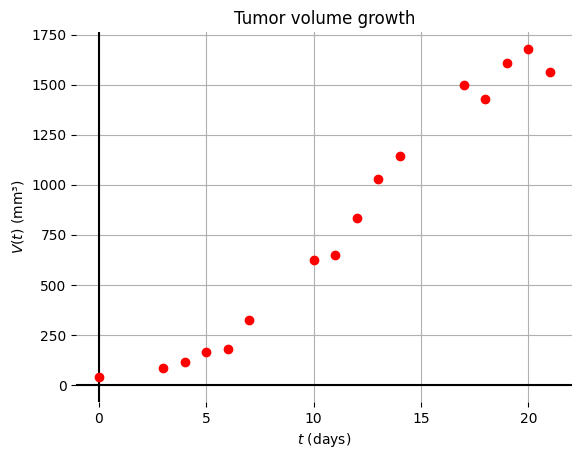

In [3]:
ts = [0, 3, 4, 5, 6, 7, 10, 11, 12, 13, 14, 17, 18, 19, 20, 21]
Vs = [41.8, 85, 114, 162.3, 178.3, 325, 623.7, 648.4, 835.9, 1030.4, 1141.8, 1499.9, 1429.3, 1609.3, 1678.3, 1564]
dt = min(np.diff(ts)) / 10
V0 = Vs[0]
t_start = ts[0]
t_end = ts[-1]

pd.DataFrame({'$t$': ts, '$V$': Vs}).T

plt.axhline(0.0, color='k'); plt.axvline(0.0, color='k')
plt.plot(ts, Vs, 'or')
plt.title('Tumor volume growth'); plt.xlabel('$t$ (days)'); plt.ylabel('$V(t)$ (mm³)')
plt.grid(True); plt.box(False)
plt.show()

Je ziet dat op dag 3 de groei van de tumor aan het begin best sloom verloopt, en dat pas op dag 7 er echt dikke stijging in komt. Op dag 18 krimpt de tumor voor een dag, voordat het weer groeit op dag 19 en z'n hoogst gemeten punt bereikt op dag 20. Op de laatste dag, dag 21, krimt het echter weer.

We hebben een tumor_models map aangemaakt, waar we alle .py bestanden gaan inzetten. Hierin hebben we de differentiaalvergelijkingen die we willen gebruiken uitgewerkt.

In [4]:
def exponential(V, c):
    return c * V

def linear(V, c):
    return c

def mendelsohn(V, c, d):
    return c * V**d

def exponential_smooth(V, c, Vmax):
    return c * (Vmax - V)

def logistic(V, c, Vmax):
    return c * V * (Vmax - V)

def montroll(V, c, d, Vmax):
    return c * V * (Vmax**d - V**d)

def allee_effect(V, c, Vmin, Vmax):
    return c * (V - Vmin) * (Vmax - V)

Bij lineare groei neemt de hoeveelheid met elke tijdseenheid met een vast aantal toe.

De groei is exponentiële groei als het afhankelijk is van de huidige hoeveelheid, de groei wordt groter dermate de hoeveelheid toeneemt. Als deze groei uiteindelijk steeds verder afneemt, is het exponentiëel afvlakkend.

Met mendelsohn bepaalt de waarde van een machtsfunctie hoe sterk de exponentiële groei is.

Bij logistische groei is de volume in het begin snel aan het groeien. Naarmate de hoeveelheid dichter bij de maximale capaciteit komt, neemt de groei snel af.

De logistische groei kan je combineren met mendelsohn groei voor montroll groei. De groei is afhankelijk van de huidige hoeveelheid, maar wordt afgeremd wanneer de volume richting de max gaat.

Als laatste hebben wij gekozen voor allee groei. Hier groeit de volume alleen als het een minimale grootte is om positieve groei mogelijk te maken.

Om de groeimodellen toe te passen op onze tumordata, moeten we die wel numeriek oplossen over verschillende tijdstippen. Hiervoor gaan we een euler methode en een huenn methode toepassen.

Ik heb hiervoor de heun solver gemaakt, waar de groeisnelheid aan het begin van de stap wordt berekent, en daarna een tijdelijk stap maakt om aan het einde daarvan de geschatte groeisnelheid ook te berekenen.Op basis van die twee stappen zou heun dan een gemiddelde definitieve stap berekenen.

In [5]:
def heun_solver(model, V0, t_start, t_end, dt, parameters):

    t = t_start
    V = V0
    times = [t]
    volumes = [V]

    while t < t_end:
        step = min(dt, t_end - t)

        growth1 = model(V, *parameters)
        t1 = t + step
        V1 = V + growth1 * step
        growth2 = model(V1, *parameters)

        t = t + step

        V = V + (growth1 + growth2) / 2 * step


        times.append(t)
        volumes.append(V)

    return times, volumes

Om te kijken of dit wat heeft gedaan, heb ik ook snel een plotje gemaakt. Ik weet nu niet even snel hoe ik dit groeiparameter mee moet geven, dus ik gebruik hiervoor wel een dummywaarde.

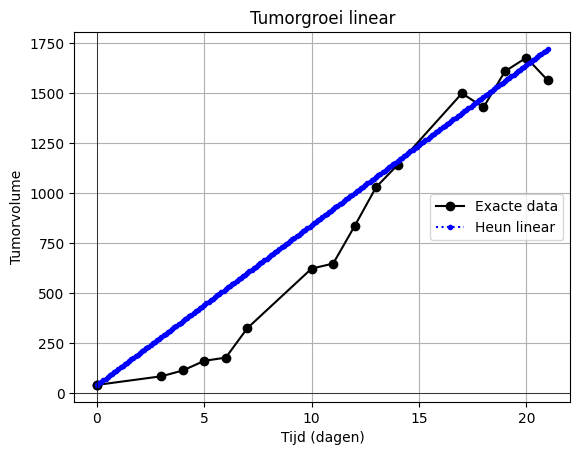

In [39]:
c = 80
t_heun, v_heun = heun_solver(linear, V0, t_start, t_end, dt, (c,))

plt.plot(ts, Vs, 'o-k', label='Exacte data')
plt.plot(ts[0], Vs[0], 'ok')
plt.plot(t_heun, v_heun, '.:b', label='Heun linear')

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei linear')
plt.show()

Nou, dit zou dan de resultaat van heun moeten zijn op de eerste muis. Hij loopt niet echt gelijk aan de exact, maar dat zou kunnen omdat dit een linear model is. Ik ga ook even kijken naar de resultaten van andere modellen om te zien of nu niet elke keer er gewoon een standaard resultaat uitkomt. Omdat ik ook geen d of Vmax/min heb, geef ik daarvoor nu ook even nog wat dummywaardes mee.

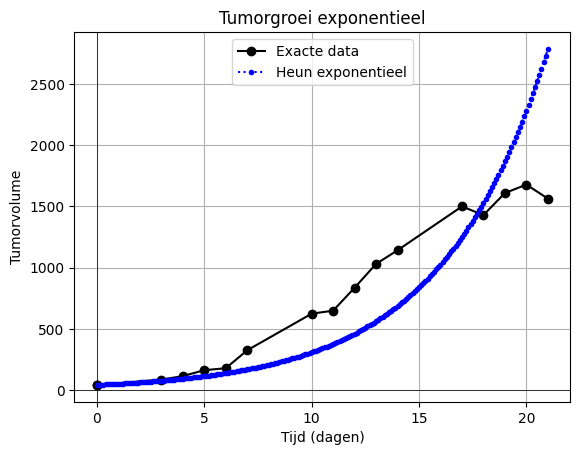

In [40]:
c = 0.2
t_heun, v_heun = heun_solver(exponential, V0, t_start, t_end, dt, (c,))

plt.plot(ts, Vs, 'o-k', label='Exacte data')
plt.plot(ts[0], Vs[0], 'ok')
plt.plot(t_heun, v_heun, '.:b', label='Heun exponentieel')

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei exponentieel')
plt.show()

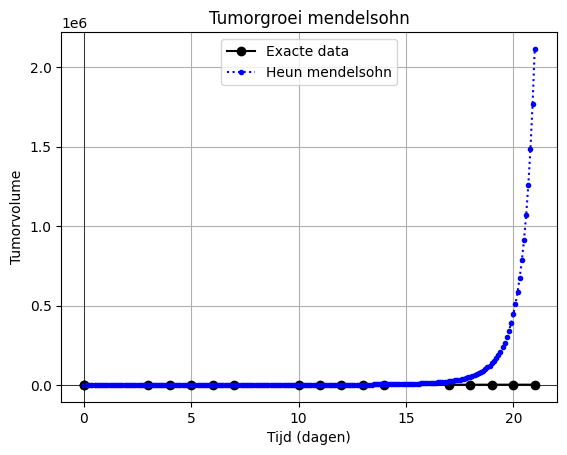

In [41]:
c = 0.1
d = 1.2
t_heun, v_heun = heun_solver(mendelsohn, V0, t_start, t_end, dt, (c, d, ))

plt.plot(ts, Vs, 'o-k', label='Exacte data')
plt.plot(ts[0], Vs[0], 'ok')
plt.plot(t_heun, v_heun, '.:b', label='Heun mendelsohn')

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei mendelsohn')
plt.show()

Nou, dat kan niet goed gegaan zijn. Ze groeien wel anders dan de lineare heun, maar ze groeien al heel snel over de exacte meting heen. Ik vermoed omdat de meegegeven waardes veels te groot zijn. Maar, dit is natuurlijk wel andere groei dan bij de lineare en exponentiële, dus de heun zelf zou goed moeten werken.

Voor morgen: De modellen optimaliseren zodat ze meer overeenkomen met de exacte data. Ook wil ik een begin maken met het accepteren van data voor het programma.

19-11-2026

Gedaan: Met de solver klaar, ga ik nu bezig met het optimaliseren van de modellen om die zo goed mogelijk overeen te laten komen met de echte gegevens. Daarvoor wil ik de nu dus de beste parameters vinden voor die data. Met iets als een monte-carlo methode zou ik dan een oplossing willekeurig veranderen, en als die beter overeenkomt de params bewaren. Als er dan na het iets van 1000 keer niks veranderd, dan zou dit een goede oplossing moeten zijn.

In [6]:
from random import gauss

def random_search_monte_carlo(t_data, V_data, model, solver, dt=1, **start_params):
    params = start_params.copy()
    parameters = list(params.values())

    times, predicted_volumes = solver(model, V_data[0], t_data[0], t_data[-1], dt, parameters)
    error = 0

    for i in range(len(t_data)):
        index = int(round((t_data[i] - t_data[0]) / dt))
        difference = V_data[i] - predicted_volumes[index]
        error += difference ** 2

    error = error / len(t_data)
    tries = 0

    while tries < 1000:
        tries += 1
        new_params = {
            key: val + gauss(0, 0.01)
            for key, val in params.items()}
        new_parameters = list(new_params.values())
        times, predicted_volumes = solver(model, V_data[0], t_data[0], t_data[-1], dt, new_parameters)
        new_error = 0

        for i in range(len(t_data)):
            index = int(round((t_data[i] - t_data[0]) / dt))
            difference = V_data[i] - predicted_volumes[index]
            new_error += difference ** 2

        new_error = new_error / len(t_data)

        if new_error < error:
            params = new_params
            error = new_error
            tries = 0

    return error, params

Na heel wat gedoe heb ik het aan de praat gekregen door parameters eerst te laten kopiëren in plaats van gelijk weg te geven aan het bepalen van de fout. Daarna wordt de fout berekend met de meegegeven solver en gekeken welke positie in de voorspelde groeicurve bij het huidige meting hoort. Het verschil tussen die twee wordt dan berekend om de kwadratische fout te krijgen. Dit wordt gedaan tot 1000 pogingen achter elkaar geen verbetering in de MSE komt. Daarna wordt een nieuwe fout berekend die de oude kan vervangen als de nieuwe waarde lager is.

Ik geef daarna de waardes van de muis en een methode mee aan monte carlo. Die zou dan de beste c, d, vmin en vmax kunnen uitreken om mee te geven als nieuw parameters voor de plots.

In [46]:
error, params = random_search_monte_carlo(ts, Vs, mendelsohn, heun_solver, dt=dt, c=0.01, d=1.0)

for key, value in params.items():
    print(f"{key} = {value}")

print(f"MSE = {error}")

c = 6.854275956852116
d = 0.38834321059371546
MSE = 11750.86039642894


Zo, en die geef ik mee aan de plots die ik bij het testen van de heun solver maakte.

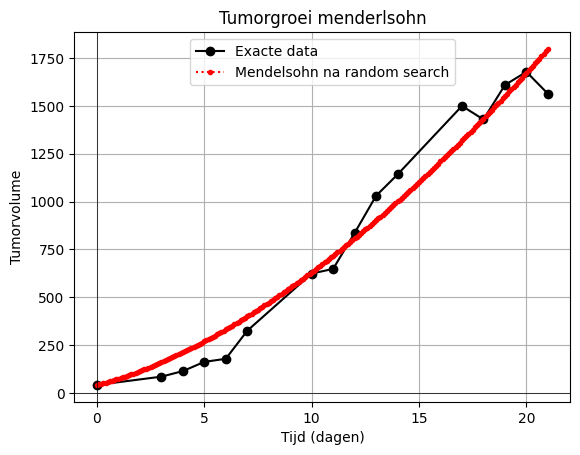

In [42]:
c = 6.667612790074842
d = 0.39285369449382496

ts_numer, Vs_numer = heun_solver(mendelsohn, Vs[0], ts[0], ts[-1], dt, [c, d])

plt.plot(ts, Vs, 'o-k', label='Exacte data')
plt.plot(ts_numer, Vs_numer, '.:r', label='Mendelsohn na random search')

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei menderlsohn')
plt.show()

In [7]:
error, params = random_search_monte_carlo(ts, Vs, allee_effect, heun_solver, dt=dt, c=0.01, Vmin=10, Vmax=2000)

for key, value in params.items():
    print(f"{key} = {value}")

print(f"MSE = {error}")

C:\Users\vdejo\AppData\Local\Temp\ipykernel_16464\2991285397.py:20: RuntimeWarning: overflow encountered in scalar multiply
  return c * (V - Vmin) * (Vmax - V)


c = 0.00015151731184738092
Vmin = 9.956616927808028
Vmax = 2000.0112873704509
MSE = 8605.487278539365


Random search heeft wel waardes kunnen vinden, maar er is ook een runtime waarschuwing gegeven. Blijkbaar zijn bij sommige parameters de tumorgegevens veels te groot berekend. De kwadraatische fout is lager dan bij mendelsohn, dus allee zou beter overeenkomen in een plot. Niet al te groot, maar is wel beter.

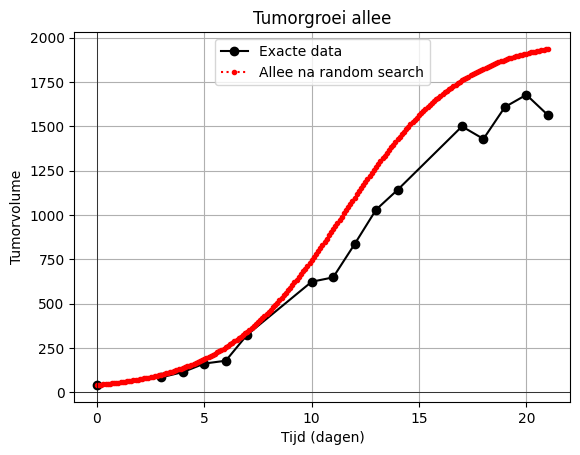

In [44]:
c = 0.00018049662139252992
Vmin = 10.031590650561421
Vmax = 2000.0198706005247

ts_numer, Vs_numer = heun_solver(allee_effect, Vs[0], ts[0], ts[-1], dt, [c, Vmin, Vmax])

plt.plot(ts, Vs, 'o-k', label='Exacte data')
plt.plot(ts_numer, Vs_numer, '.:r', label='Allee na random search')

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei allee')
plt.show()

Je zou zeggen dat ondanks de kwadraatishe fout, de lijn van allee minder overeenkomt met de exacte lijn dan bij bijvoorbeeld mendelsohn. Maar hij vlakt wel af op het einde, dus ik snap wel dat de MSE hier lager licht. Verder heeft het wel een andere vorm dan de mendelsohn, dus dat wordt wel goed gedaan. Ik kijk nog even verder naar het logaritmische groeimodel.

In [8]:
error, params = random_search_monte_carlo(ts, Vs, logistic, heun_solver, dt=dt, c=0.01, Vmax=2000)

for key, value in params.items():
    print(f"{key} = {value}")

print(f"MSE = {error}")

C:\Users\vdejo\AppData\Local\Temp\ipykernel_16464\2991285397.py:14: RuntimeWarning: overflow encountered in scalar multiply
  return c * V * (Vmax - V)


c = 0.00014223664103593938
Vmax = 2000.0072281101925
MSE = 6508.517014837182


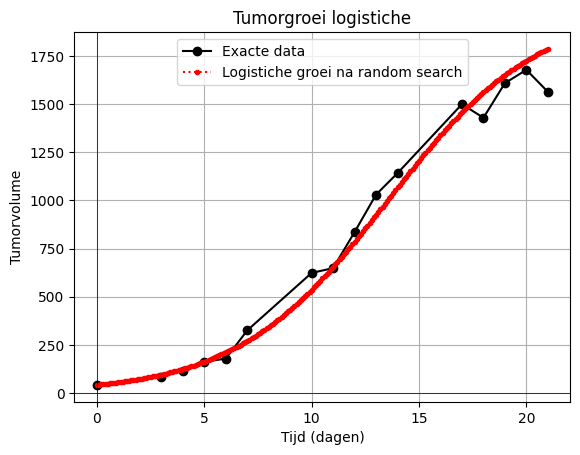

In [26]:
c = 0.00014223664103593938
Vmax = 2000.0072281101925

ts_numer, Vs_numer = heun_solver(logistic, Vs[0], ts[0], ts[-1], dt, [c, Vmax])

plt.plot(ts, Vs, 'o-k', label='Exacte data')
plt.plot(ts_numer, Vs_numer, '.:r', label='Logistiche groei na random search')

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei logistiche')
plt.show()

Een MSE van 6508 is klein, en dus best mooi. Ook komt de logaritmiche voorspelling mooi overeen met de exacte data. Ik ben er nu vrij zeker van dat de optimalisatie goed is gegaan, yay!

Voor morgen: De comparison stap moet nog gedaan worden, maar daarna zouden we klaar zijn met code. Daarna een voorbeeld van de use case doen, misschien voor zowel heun als euler? Komt vast goed.

22-11-2026

Gedaan: Vandaag ga ik bezig met de laatste stap, de comparison. Een lagere MSE betekent niet automatisch at dit de beste verklaring voor de data is. Als je model veel parameters heeft, kan je al snel overfitting krijgen. Je hebt hiervoor drie statistische vergelijkingsmaten: BIC, AIC, en AICc. Als je een grote MSE krijgt, dan zullen deze maten ook hoger worden. Echter, deze maten zullen ook groeien bij de hoeveelheid parameters. BIC geeft strafpunten aan modellen met veel parameters en hoge metingen, AIC geeft strafpunten aan parameters maar de grote maakt hem niet zo veel uit en AICc geeft een correctie aan met datasets met een relatief kleine hoeveelheid meetgegevens.

We gaan dus onze modellen na monte carlo hierdoor heen halen, om te zien of de gemiddelde kwadraatische fout niet door overfitting komt. Hiervoor moet ik eerst die maten opstellen.

In [13]:
def calculate_aic(error, n, k):
    return n * log(error) + 2 * k


def calculate_aicc(error, n, k):
    return n * log(error) + (2 * k * n) / (n - k - 1)


def calculate_bic(error, n, k):
    return n * log(error) + k * log(n)


Deze formules heb ik overgenomen uit Workshop 4. Ze gebruiken allemaal de MSE, het aantal meetpunten en het aantal parameters. Daarna hebben ik met wat code van fleur een functie gemaakt die deze berekeningen combineert met de random search. Zo kan ik meerdere groeimodellen en numerieke solvers met elkaar vergelijken.

In [17]:
from ModellerenVanKankerCasusA.tumor_models.monte_carlo import random_search_monte_carlo

def compare_models(t_data, V_data, models, solvers, start_parameters, dt=1):
    results = []
    n = len(t_data)

    for model_name, model in models.items():
        for solver_name, solver in solvers.items():
            error, params = random_search_monte_carlo(t_data, V_data, model, solver, dt,**start_parameters[model_name])
            k = len(params)

            if error > 0:
                aic = calculate_aic(error, n, k)
                aicc = calculate_aicc(error, n, k)
                bic = calculate_bic(error, n, k)
            else:
                aic = None
                aicc = None
                bic = None

            results.append({"model": model_name, "solver": solver_name, "error": error, "parameters": params,
            "AIC": aic, "AICc": aicc, "BIC": bic})

    return results

In [20]:
from ModellerenVanKankerCasusA.tumor_models.solver_euler import euler_solver

models = {
    "Mendelsohn": mendelsohn,
    "Exponential": exponential,
    "Linear": linear,
    "Exponential smooth": exponential_smooth,
    "Logistic": logistic,
    "Montroll": montroll,
    "Allee": allee_effect}

solvers = {"Euler": euler_solver, "Heun": heun_solver}

start_parameters = {
    "Mendelsohn": {"c": 0.01, "d": 1.0},
    "Exponential": {"c": 0.1},
    "Linear": {"c": 10},
    "Exponential smooth": {"c": 0.001, "Vmax": 2000},
    "Logistic": {"c": 0.00001, "Vmax": 2000},
    "Montroll": {"c": 0.000001, "d": 1.0, "Vmax": 2000},
    "Allee": {"c": 0.00001, "Vmin": 10, "Vmax": 2000}}

results = compare_models(ts, Vs, models, solvers, start_parameters, dt=dt)

C:\Users\vdejo\AppData\Local\Temp\ipykernel_16464\2991285397.py:14: RuntimeWarning: overflow encountered in scalar multiply
  return c * V * (Vmax - V)
C:\Users\vdejo\PycharmProjects\Kankermodell\ModellerenVanKankerCasusA\tumor_models\monte_carlo.py:49: RuntimeWarning: overflow encountered in scalar power
  new_error += difference ** 2
C:\Users\vdejo\AppData\Local\Temp\ipykernel_16464\2991285397.py:17: RuntimeWarning: invalid value encountered in scalar power
  return c * V * (Vmax**d - V**d)
C:\Users\vdejo\AppData\Local\Temp\ipykernel_16464\2991285397.py:20: RuntimeWarning: overflow encountered in scalar multiply
  return c * (V - Vmin) * (Vmax - V)


In deze functie worden eerst alle modellen en solvers doorlopen. Voor iedere combinatie wordt dan de monte carlo random search. Daarna worden de AIC AICc en BIC berekend. Als de MSE nul of lager is, worden de scores op None gezet, omdat de logaritme van nul of een negatief getal niet berekend kan worden.

In [21]:
for result in results:
    print("Model:", result["model"])
    print("Solver:", result["solver"])
    print("Error:", result["error"])
    print("Parameters:", result["parameters"])
    print("AIC:", result["AIC"])
    print("AICc:", result["AICc"])
    print("BIC:", result["BIC"])
    print("----------------------")

Model: Mendelsohn
Solver: Euler
Error: 11781.565820897886
Parameters: {'c': 6.471122038860557, 'd': 0.3985056948766843}
AIC: 153.98866192559973
AICc: 154.91173884867666
BIC: 155.53383937007928
----------------------
Model: Mendelsohn
Solver: Heun
Error: 11761.77029660455
Parameters: {'c': 6.684361642407337, 'd': 0.3924337778132861}
AIC: 153.96175592878168
AICc: 154.88483285185862
BIC: 155.50693337326123
----------------------
Model: Exponential
Solver: Euler
Error: 107643.77317434913
Parameters: {'c': 0.18918064213723856}
AIC: 187.38532252594385
AICc: 187.67103681165813
BIC: 188.15791124818364
----------------------
Model: Exponential
Solver: Heun
Error: 107643.81870826447
Parameters: {'c': 0.1874172588010924}
AIC: 187.3853292940315
AICc: 187.67104357974577
BIC: 188.15791801627128
----------------------
Model: Linear
Solver: Euler
Error: 29395.653803882822
Parameters: {'c': 74.0060904297727}
AIC: 166.61763380158348
AICc: 166.90334808729776
BIC: 167.39022252382327
----------------------

Dit zijn de de resultaten van alle 6 modellen door beide solvers heen gehaald. Blijkbaar had de logistische vergelijking met een MSE van 6759,99, een AIC van 145,10 een AICc van 146,02 en een BIC	van 146,65 daadwerkelijk de meeste overeenkomst met de data van de testmuis die we hebben genomen als vergelijking. Ik ga het nog even plotten met de gekozen parameters voor een goede weergave.

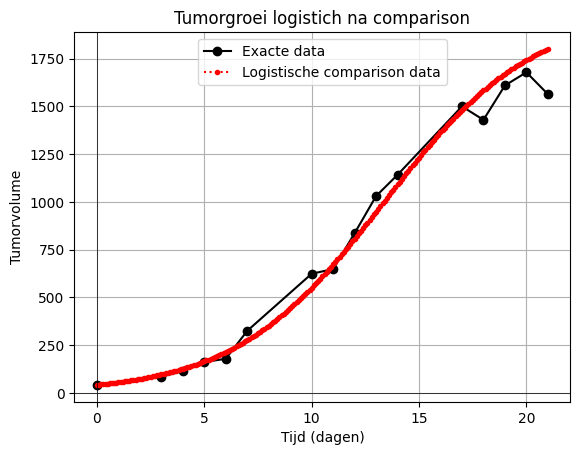

In [25]:
c = 0.00014401763491462706
Vmax = 1999.9935203164353

ts_numer, Vs_numer = heun_solver(
    logistic, Vs[0], ts[0], ts[-1], dt, [c, Vmax])

plt.plot(ts, Vs, 'o-k', label='Exacte data')
plt.plot(ts_numer, Vs_numer, '.:r', label='Logistische comparison data')

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei logistich na comparison')
plt.show()

Nou, daar is onze grote vriend de logistiche vergelijking weer. Dat het als de beste vergelijking voor deze specifieke tumorgroei uit de comparison komt, is waarschijnlijk omdat in het begin de tumor relatief langzaam groeit. Daarna neemt de groeisnelheid toe. Wanneer het tumorvolume dichter bij de Vmax komt, neemt de groeisnelheid weer af. Ook heeft het logistische model maar twee parameters en krijgt het dus geen extra straf voor overfitten door te complexe parameters.

Als laatste, twee plotjes met de vergelijkingen van alle modellen en solvers.

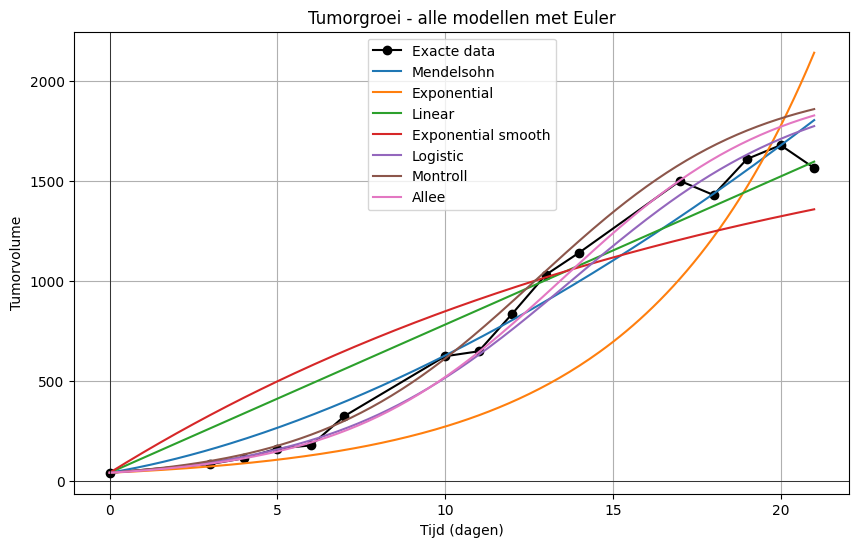

In [23]:
plt.figure(figsize=(10, 6))

plt.plot(ts, Vs, 'o-k', label='Exacte data')

for result in results:
    if result["solver"] == "Euler":
        model_name = result["model"]
        model = models[model_name]
        parameters = list(result["parameters"].values())

        ts_numer, Vs_numer = euler_solver(model, Vs[0], ts[0], ts[-1], dt, parameters)
        plt.plot(ts_numer, Vs_numer, label=model_name)

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei van alle modellen met euler')
plt.show()

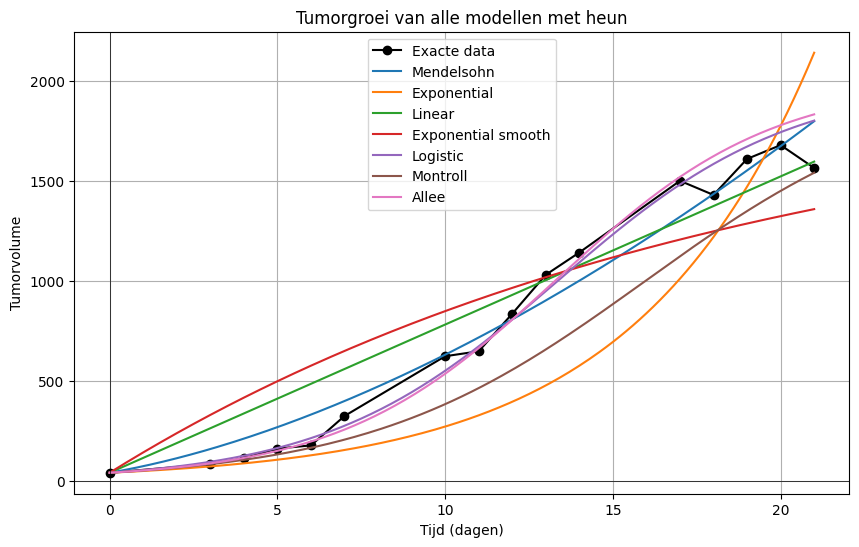

In [24]:
plt.figure(figsize=(10, 6))

plt.plot(ts, Vs, 'o-k', label='Exacte data')

for result in results:
    if result["solver"] == "Heun":
        model_name = result["model"]
        model = models[model_name]
        parameters = list(result["parameters"].values())

        ts_numer, Vs_numer = heun_solver(model, Vs[0], ts[0], ts[-1], dt, parameters)
        plt.plot(ts_numer, Vs_numer, label=model_name)

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei van alle modellen met heun')
plt.show()

23-11-2026

De use case file aangemaakt met de informatie uit dit logboek. Voor de rest wat schoongemaakt her en der.